[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ScriptsRemote/Transcend_SummerSchool/blob/main/Day2_Hydroeconomics_and_Water_Mapping/02_sensors_and_spectral_behaviour_es.ipynb)

# Día 2 - Hidroeconomía y Mapeo del Agua
## Sesión 2: Sensores y comportamiento espectral

| | |
|---|---|
| **Fecha** | 2026-10-13 (martes) |
| **Horario** | 10:40 - 12:10 |
| **Entidad** | SEI / IMDEA |
| **Instructores** | Christhian, Sebastian |

### Contenido

> Adquisición de datos y sistemas sensores. Resolución espacial, espectral, radiométrica y temporal (Landsat, Sentinel, MODIS). Comportamiento espectral de la vegetación, el suelo y el agua

### Objetivos de aprendizaje

- [ ] Explicar las cuatro resoluciones de un sistema de teledetección (espacial, espectral, temporal, radiométrica) y las compensaciones entre ellas
- [ ] Conectarse a Google Earth Engine desde Python (`ee` + `geemap`) y definir un área de interés de forma interactiva en un mapa
- [ ] Construir e interpretar composiciones en color natural y en falso color para Landsat 8, MODIS y Sentinel-2
- [ ] Comparar el mismo objetivo en la misma fecha con tres sensores y explicar las diferencias a partir de sus resoluciones

### Datos necesarios

No se necesitan archivos locales: todas las imágenes se transmiten desde el catálogo de Google Earth Engine.
Se requiere una **cuenta gratuita de Earth Engine** (ver la sección 2.2).

| Colección | Producto | Uso |
|---|---|---|
| `LANDSAT/LC08/C02/T1_L2` | Landsat 8 Surface Reflectance | composiciones de 30 m |
| `MODIS/061/MOD09A1` | MODIS Terra Surface Reflectance, 8 días | composiciones de 500 m |
| `COPERNICUS/S2_SR_HARMONIZED` | Sentinel-2 Surface Reflectance | composiciones de 10-20 m |

---


## 2.1 - Teoría

###  ¿Qué es la teledetección?
La teledetección es la **práctica de obtener información** sobre la superficie de la Tierra por medio de imágenes
adquiridas desde el espacio, utilizando la radiación electromagnética reflejada o emitida, en una o más regiones del
espectro electromagnético.

Las imágenes de teledetección pueden ser producidas por sensores a bordo de plataformas orbitales (satélites) y aerotransportadas (aviones y UAV), que captan la radiación electromagnética que sale de la superficie terrestre hacia el espacio. Esta información es extremadamente importante para modelos de precipitación, contaminación, antropización y vulnerabilidad a desastres, principalmente porque no es puntual, y constituye una fuente continua de datos sobre grandes áreas.

Con la llegada de la fotografía y la fotogrametría, el ser humano buscó diversas formas de obtener una vista desde arriba de la superficie terrestre — usando globos, palomas, aviones y cohetes, como muestran los ejemplos de abajo. Este cambio de perspectiva fue fundamental para superar nuestras limitaciones visuales en el terreno, permitiendo mapear grandes áreas y dando una nueva comprensión del espacio geográfico. Fue justamente esta creciente necesidad de monitorear la Tierra de forma continua, amplia y precisa la que impulsó los avances tecnológicos hasta llegar a la ciencia moderna de la teledetección.

a) <img src="https://infoportugal.pt/wp-content/uploads/2020/03/Pombos_Camara.jpg" width="500"> b)<img src="https://nypost.com/wp-content/uploads/sites/2/2014/06/wwi-anniversary_-3.jpg?resize=768,1024&quality=90&strip=all" width="200">

Fig 1 - a) Adquisición de imágenes aéreas usando palomas en 1907 - Dr. Julius Neubronner y b) Una fotografía aérea muestra trincheras en el Frente Occidental el 17 de junio de 1917

La teledetección moderna comenzó en 1972, con el lanzamiento del primer satélite de imágenes de la serie Landsat por el gobierno de los Estados Unidos. Este satélite llevaba a bordo el sensor Multispectral Scanner System (MSS), con imágenes digitales en cuatro bandas espectrales y píxeles de 80 m (Zanota et al, 2019). Una vez reconocido el gran potencial asociado a la observación periódica de grandes áreas de la superficie terrestre, otros países comenzaron a desarrollar programas espaciales y a lanzar satélites cada vez más avanzados. Hoy, los satélites
son capaces de adquirir imágenes en decenas o cientos de bandas espectrales, con tamaños de píxel que van desde unos pocos centímetros hasta kilómetros, según la aplicación a la que están destinados.

<div style="width:200px">

![image.png](https://raw.githubusercontent.com/ScriptsRemote/Transcend_SummerSchool/main/Figures/Day2/02_c02_image.png)

</div>

Fig 2 - Landsat 1 en configuración de vuelo con los paneles solares desplegados después de las pruebas en la planta G.E. Valley Forge, 1972.

Como señala Baptista (2023), además del Landsat 1 se lanzaron otros satélites de esta serie, y es considerado el sistema más explotado, con el mayor número de artículos
publicados a partir de sus datos hasta la fecha. De todos ellos, solo el número 6 no obtuvo imágenes, ya que quedó inoperativo después de su lanzamiento.

<video src="https://usgs-ocapsv2-public-output-media.s3.us-west-2.amazonaws.com/assets/palladium/production/s3fs-public/l8swath/MP4/l8swath.mp4"
       width="600" controls loop muted playsinline></video>

Fig 3 - Adquisición de imágenes por Landsat - representación

Aunque fundamentales, los sensores ópticos (como los de la serie Landsat) dependen de la luz solar y no pueden registrar la superficie cuando el cielo está cubierto. Para superar el problema de las nubes, la teledetección también usa sistemas activos, como el Radar de Apertura Sintética (SAR). En lugar de depender de la iluminación del Sol, un satélite que lleva un radar emite su propio pulso de energía en el rango de las microondas y mide la señal que se refleja de vuelta desde la superficie. Esto permite adquirir imágenes tanto de día como de noche, independientemente de las condiciones meteorológicas.

<div style="display:flex; gap:12px; align-items:flex-start; text-align:center">
  <div style="flex:1">
    <img src="https://earthdata.nasa.gov/s3fs-public/styles/hds_large/public/2022-02/SARPolarization.jpg?VersionId=KyQ7vrmGXFfSLVdRu6r8oMCEiSy.uiuu&itok=TPctruIs" style="width:100%; height:180px; object-fit:contain">
    <br><small>(a) Mecanismos de dispersión: superficie rugosa, volumen y doble rebote</small>
  </div>
  <div style="flex:1">
    <img src="https://earthdata.nasa.gov/s3fs-public/styles/hds_large/public/imported/SARtree_figure2.jpg?VersionId=39oxzCRneDXVdpdJUtc_MO.Rgwnr4cDd&itok=_u1-xSiS" style="width:100%; height:180px; object-fit:contain">
    <br><small>(b) Penetración en el dosel según la longitud de onda (bandas X, C, L, P)</small>
  </div>
  <div style="flex:1">
    <img src="https://earthdata.nasa.gov/s3fs-public/2023-01/sentinel-1_sar_turkey.jpg?VersionId=0QoLtC45D9C7RcRFoQp80j7I.z6eVJmH" style="width:100%; height:180px; object-fit:contain">
    <br><small>(c) Adquisición Sentinel-1, banda C</small>
  </div>
</div>

Fig 4 - Cómo interactúa el SAR con la superficie: el mecanismo de dispersión que devuelve la señal (a), hasta dónde penetra cada longitud de onda en el dosel (b) y la imagen resultante de un sensor operativo en banda C (c). Fuente: NASA Earthdata.

Diferentes misiones basadas en la tecnología SAR cumplen funciones esenciales en la observación de la Tierra. La **misión SRTM**, por ejemplo, usó radares de apertura sintética para mapear la elevación y el relieve a escala global. Satélites como el **ALOS japonés** trajeron grandes avances al monitoreo de la cobertura del suelo usando esta misma tecnología, mientras que la actual constelación europea **Sentinel-1** proporciona datos SAR continuos, aplicados desde la detección de inundaciones hasta el monitoreo agrícola. El desarrollo sigue avanzando con un enfoque en temas específicos, como en el caso de la futura misión **Biomass**, diseñada con un radar que opera en una frecuencia capaz de medir la estructura y el volumen de la biomasa forestal global.

<div style="display:flex; gap:10px; align-items:flex-start; text-align:center">
  <div style="flex:1">
    <img src="https://www.arcgis.com/sharing/rest/content/items/011a9efe78804f18bd002efe90956994/info/thumbnail/ago_downloaded.jpg?w=800" style="width:100%;object-fit:contain">
    <br><small>(a) SRTM - banda C</small>
  </div>
  <div style="flex:1">
    <img src="https://earthdata.nasa.gov/s3fs-public/styles/hds_hero_half/public/2024-10/alos-palsar-project-hero-1.jpg?VersionId=rOfotItYGoqhXz7lpFEcsol8LKL0qZeK&itok=_3YzYygc" style="width:100%;object-fit:contain">
    <br><small>(b) ALOS PALSAR - banda L</small>
  </div>
  <div style="flex:1">
    <img src="https://www.esa.int/var/esa/storage/images/esa_multimedia/images/2025/02/seeing_the_wood_through_the_trees/26571714-1-eng-GB/Seeing_the_wood_through_the_trees_pillars.png" style="width:100%">
    <br><small>(c) Biomass - banda P</small>
  </div>
</div>

Fig 5 - Misiones SAR y bandas del espectro de microondas: cuanto mayor es la longitud de onda, mayor es la penetración en el dosel. Fuentes: Esri/NASA JPL (SRTM), NASA Earthdata/JAXA (ALOS PALSAR), ESA/ATG medialab CC BY-SA 3.0 IGO (Biomass).

Finalmente, además del avance continuo de los satélites ópticos y de radar, la tecnología de sensores se ha reducido en tamaño y peso, lo que permite que los sensores operen mucho más cerca del suelo. Aquí entran los **Vehículos Aéreos No Tripulados (UAV o drones)**. Mientras los satélites garantizan la observación continua de grandes extensiones de terreno, los drones complementan este trabajo a nivel local. Ofrecen una resolución espacial del orden de centímetros y la flexibilidad de volar el día exacto y a la hora exacta en que se necesitan los datos, lo que los convierte en herramientas indispensables para el mapeo de precisión.

<img src="https://media.licdn.com/dms/image/v2/C4D22AQHkakNimUnaVA/feedshare-shrink_800/feedshare-shrink_800/0/1663874568242?e=2147483647&v=beta&t=8fwlPqN_G_eNkxQrwSyBo2eu1so2S6I8mp-tZPrZ210" width="600">

Fig 5 - NDVI por parcela usando imágenes de dron.

### Qué registra realmente un sensor

En la teledetección para la observación de la Tierra, los sistemas sensores fueron diseñados para ofrecer imágenes con distintas características geométricas, espectrales y temporales. Estos datos se recolectan registrando la **radiación electromagnética (REM)** reflejada o emitida por el objetivo en la superficie terrestre en **diferentes longitudes de onda** del **espectro electromagnético**. Los sensores remotos son capaces de captar las respuestas espectrales de diferentes regiones del espectro electromagnético, mucho más de lo que puede ver el ojo humano (luz visible).

La energía que emana de la superficie puede provenir de la intensa reflexión de la luz solar que ilumina los objetivos terrestres (teledetección pasiva reflectiva) o de la emisión directa de radiación térmica por los materiales de la superficie (teledetección pasiva emisiva). Una imagen de teledetección también puede originarse en la reflexión de la **energía artificial** producida por el propio satélite, que fue dirigida a la superficie y luego captada por el sensor, como ocurre en las **imágenes de radar** (Radio Detection and Ranging) o **Lidar** (Light Detection and Ranging), que corresponden a la teledetección activa.

La radiación solar, que viaja por el vacío hasta llegar a la Tierra, **incide primero en la región más externa de la atmósfera**, llamada **tope de la atmósfera**. A partir de ese punto, la radiación comienza a **interactuar** con diversos componentes atmosféricos, siendo **absorbida**, **dispersada** y **reflejada** por gases como el oxígeno y el ozono, el vapor de agua, el dióxido de carbono y partículas de diferentes tamaños. Una vez en contacto con la **superficie**, la radiación puede ser absorbida o reflejada de vuelta al espacio. El tipo de interacción depende tanto de la composición química y física del objetivo como de la longitud de onda de la radiación incidente.

En el ejemplo de abajo podemos ver el proceso de recolección de datos a nivel orbital desde un sensor de imágenes. Parte de la **radiación solar** que incide en la superficie terrestre es **reflejada** de vuelta al espacio y es **captada por el sensor del satélite**. Los datos de la imagen se envían por telemetría a estaciones receptoras ubicadas en la superficie, donde se preprocesan y se ponen a disposición de los usuarios. Uno de los principales productos de la teledetección, las **imágenes digitales**, está formado por conjuntos de píxeles (elementos de imagen)
que describen la cantidad de energía que sale de una porción definida de la superficie. Lo que aquí se entiende por energía no es más que distintas formas de **onda o radiación electromagnética**. Toda **radiación electromagnética** tiene propiedades fundamentales y comportamientos predecibles según la teoría física. Es a través del conocimiento
previo de estas interacciones que se pueden **interpretar los objetivos en la superficie** a partir de la **cantidad de radiación que fue reflejada o emitida** por ellos.

<img src="https://cdn-fnoci.nitrocdn.com/ThwtfMtLrzDTNYOmsRitVsOalzfIZLRK/assets/images/optimized/rev-441541a/i0.wp.com/geolearn.in/wp-content/uploads/2022/09/9752c29b48640038080ec50e60b23dad.Remote-Sensing-Process.jpg" width="600">

Fig 6 - Adquisición y procesamiento de datos de teledetección.
Fuente:(Lucrêncio et al, 2021).

La diversidad de radiación producida por el Sol se clasifica comúnmente en rangos específicos de longitud de onda que comparten características similares de interacción con la materia o de aplicación práctica en la Tierra. Esta clasificación se **llama espectro electromagnético**, y su división es subjetiva y puede variar según la aplicación y la referencia utilizada.

El **espectro electromagnético** es una forma de representar, de manera ordenada, las principales regiones de la radiación en función de sus longitudes de onda. Comienzan con los rayos cósmicos, los rayos gamma y los rayos X, todos con longitudes del orden del picómetro (pm) o 10-12m. Luego viene la región del ultravioleta, seguida por la **región de la luz visible y del infrarrojo**, que se expresan en **nanómetros (nm)** o 10-9m y en **micrómetros (µm)** o 10-6m. A partir de las microondas, las longitudes de onda se expresan en milímetros (mm) o 10-3m, y las ondas de radio van
del metro (m) al kilómetro (km).

<img src="https://b3801007.assetcdn.net/3801007/wp-content/uploads/2022/06/electromagnetic-EM-spectrum.png?lossy=2&strip=1&webp=1" width="600">

Debido a la diferente **composición química y física** de los objetivos en la superficie terrestre, es natural que los materiales presenten **comportamientos diversos frente a la radiación electromagnética**. En un mismo material pueden ocurrir simultáneamente, por ejemplo, **absorción, transmisión y reflexión en cantidades variables**, según
la combinación de los elementos que lo componen. Por lo tanto, si cada material presenta un **comportamiento único** frente a la radiación incidente, entonces es posible identificar su composición química a partir de él.

El gráfico de abajo ilustra la **firma espectral de diferentes superficies**, mostrando cómo **absorben o reflejan la radiación a lo largo de las longitudes de onda**. La **curva de la vegetación** se destaca en el espectro visible por su fuerte absorción en los rangos del azul y del rojo, energía consumida por los pigmentos de clorofila durante la fotosíntesis, lo que hace que **refleje predominantemente en el verde**. Al llegar al infrarrojo cercano, la reflectancia de la planta da un salto marcado, porque la estructura celular interna de las **hojas sanas** dispersa y refleja intensamente esa radiación, invisible a nuestros ojos. Más adelante, en el **infrarrojo de onda corta**, se observan caídas profundas de la reflexión; estos "valles" de absorción ocurren porque la **humedad (agua) contenida en los tejidos vegetales retiene fuertemente la energía**. En marcado contraste, una superficie de agua pura absorbe prácticamente toda la radiación incidente, reduciendo su reflexión a cero ya al inicio del infrarrojo. Por otro lado, los **objetivos minerales como la arena y el suelo seco** presentan un aumento gradual y constante de la reflectancia en todo el espectro, sin las caídas abruptas causadas por el agua en la vegetación, mientras que las áreas urbanas muestran un comportamiento reflectivo intermedio y más irregular.

<img src="https://media.springernature.com/full/springer-static/image/art%3A10.1038%2Fs41598-018-27905-0/MediaObjects/41598_2018_27905_Fig11_HTML.jpg?as=webp" width="400">

Fig 7 - Reflectancia del agua, la vegetación, el suelo y las áreas urbanas residenciales en el espectro de 0.4–2.5 μm.
Fuente: Pan et al (2018)

Las bandas espectrales (o canales espectrales) son los **segmentos del espectro electromagnético** para los que los sensores a bordo de los satélites están diseñados para adquirir imágenes. A pesar de la **extensión del espectro electromagnético**, pocas regiones se usan en aplicaciones de teledetección – solo aquellas en las que la radiación no es absorbida por la atmósfera terrestre y aquellas en las que los sensores tienen sensibilidad tienen aplicaciones prácticas.

---

### Resoluciones de las imágenes satelitales

Las imágenes producidas por los sensores de imágenes tienen diferentes resoluciones, que influyen en la detección o identificación de un objeto. Son:
* resolución espacial
* resolución espectral
* resolución radiométrica
* resolución temporal.

### 1. Resolución espacial - *¿qué tan pequeño es el objeto más pequeño que puedo ver?*

La resolución espacial "se refiere a la capacidad del sistema sensor para distinguir y medir objetivos".
Es un parámetro importante, ya que determina el tamaño del objeto más pequeño que se puede detectar en la imagen, y está directamente relacionado con el píxel. **Cuanto menor es el tamaño del píxel**, **mayor es la resolución espacial de la imagen**, ya que mayor es el detalle de los objetos que se pueden ver para una misma área.

El área en el terreno representada por un píxel:

- Landsat 8/9 OLI: **30 m** (un píxel cubre 900 m2, aproximadamente el área penal de una cancha de fútbol)
- Sentinel-2 MSI: **10 m** en el visible/NIR, **20 m** en el red-edge y el SWIR
- MODIS: **250 m / 500 m / 1000 m** según la banda

![image.png](https://raw.githubusercontent.com/ScriptsRemote/Transcend_SummerSchool/main/Figures/Day2/02_c04_image.png)

Fig 8 - Diferentes resoluciones espaciales

Regla práctica: para *detectar* un objeto de forma confiable, conviene que tenga al menos **2-3 píxeles
de ancho**. Un canal de riego de 20 m de ancho es invisible a 500 m (MODIS), una señal mixta a 30 m
(Landsat) y detectable a 10 m (Sentinel-2). Cualquier cosa menor que un píxel produce un
**píxel mixto**: el valor registrado es el promedio ponderado de agua, suelo y vegetación
dentro de esa celda, que es la fuente de error más común en el mapeo de embalses pequeños.

### 2. Resolución espectral - *¿cuántos colores, y qué tan estrechos?*

El número de bandas y el ancho de cada una. Más bandas, y más estrechas, significan una descripción
más fina de la superficie, a costa de menos energía por banda.

- Landsat 8: 9 bandas reflectivas (costera, azul, verde, rojo, NIR, 2 SWIR, pancromática, cirros) + 2 térmicas
- Sentinel-2: 13 bandas, incluidas 3 bandas **red-edge** que Landsat no tiene -
  el red-edge es donde el estrés de la vegetación se manifiesta primero
- MODIS: 36 bandas, diseñadas para el monitoreo global de la atmósfera/océano/tierra más que para el mapeo fino

El gráfico de abajo ilustra la relación técnica entre la transmitancia atmosférica y la ubicación estratégica de las bandas espectrales de diferentes sensores orbitales. El área de fondo representa las "ventanas atmosféricas"

<img src="https://pbs.twimg.com/media/Cr2V5GJUAAAU6DX?format=jpg&name=large" width="600">

Fig 9 - Gráfico comparativo aproximado de las bandas espectrales de Landsat, MODIS y Sentinel-2.

Fuente: USGS (2016)

### 3. Resolución temporal - *¿cada cuánto obtengo una nueva imagen?*

El intervalo de revisita de un mismo punto en el terreno.

- Landsat 8 solo: **16 días**; combinando Landsat 8 + 9 se obtienen **~8 días**
- Sentinel-2 A + B: **~5 días** en el ecuador, 2-3 días en latitudes medias
- MODIS: **1-2 días** (por eso las composiciones de 8 y 16 días son los productos estándar)
 - GOES / Meteosat (geoestacionarios): de 10 a 15 minutos. Ubicados a ~36 000 km, observan el mismo hemisferio de forma continua, sacrificando el detalle espacial (1-2 km) a cambio del monitoreo en tiempo real.

Para la hidrología y la gestión de desastres, esta escala es decisiva. Una crecida repentina o el inicio súbito de un incendio podría simplemente no existir en un archivo Landsat de 16 días. MODIS verá la progresión diaria a 500 m, mientras que un sensor geoestacionario como GOES captará la hora exacta en que comenzó el evento, aunque con una resolución mucho más gruesa. Si se suma la cobertura de nubes, la revisita efectiva de los sensores ópticos se vuelve mucho más larga que la nominal.

![image-2.png](https://raw.githubusercontent.com/ScriptsRemote/Transcend_SummerSchool/main/Figures/Day2/02_c04_image-2.png)

Fig 10 - Ejemplo de las imágenes disponibles para una misma área usando Landsat, MODIS y Sentinel-2.


### 4. Resolución radiométrica - *¿cuántos tonos puedo distinguir?*

También conocida como cuantización, la resolución radiométrica de una imagen puede entenderse como la capacidad del sensor para registrar diferentes niveles de gris. Cada píxel puede tomar valores que van del negro al blanco, con el nivel específico determinado por la cantidad de radiación que proviene de la superficie. Cuantos más niveles de gris muestra una imagen, mayor (o mejor) es su resolución radiométrica. Esto se refiere al número de niveles usados para cuantizar la señal, expresado en bits.

| Bits | Niveles | Ejemplo |
|---|---|---|
| 8 bit | 256 | Landsat 5 TM (histórico) |
| 12 bit | 4096 | Landsat 8 OLI, Sentinel-2 MSI, MODIS |
| 16 bit | 65536 | formato de almacenamiento de los productos de la Colección 2 |

Una mayor resolución radiométrica significa que los contrastes sutiles se conservan: los objetivos oscuros como el **agua**
y la **sombra** ocupan la parte más baja del rango, de modo que el OLI de 12 bits separa el agua turbia del
agua clara donde el antiguo TM de 8 bits saturaba todo cerca de cero.

> Como los valores se almacenan como enteros escalados, **cada producto debe reescalarse a reflectancia
> física (0-1) antes de usarlo**. Landsat Colección 2 L2 usa `0.0000275 * DN - 0.2`;
> MODIS MOD09A1 y Sentinel-2 L2A usan `DN * 0.0001`. Lo hacemos en cada bloque de abajo.

---

### Resumen comparativo

| | **Landsat 8/9 (OLI)** | **Sentinel-2 (MSI)** | **MODIS (Terra/Aqua)** |
|---|---|---|---|
| Espacial | 30 m (15 m pancromática) | 10 / 20 / 60 m | 250 / 500 / 1000 m |
| Espectral | 9 reflectivas + 2 térmicas | 13 bandas (incl. red-edge) | 36 bandas |
| Temporal | 16 d (8 d con ambos) | ~5 d | 1-2 d |
| Radiométrica | 12 bit | 12 bit | 12 bit |
| Ancho de barrido | 185 km | 290 km | 2330 km |
| Archivo | 1972 (Landsat 1) / 2013 (L8) | 2015 | 2000 |
| Más adecuado para | series temporales largas, detalle medio | detalle a escala de parcela, monitoreo de cultivos | dinámicas a gran escala y alta frecuencia |

**La compensación en una línea:** MODIS ve *todo, con frecuencia, de forma gruesa*; Sentinel-2 ve
*mucho detalle, con menos frecuencia*; Landsat se ubica en el medio y, de forma decisiva, tiene el **archivo
más largo** - por eso sigue siendo la referencia para los cambios a lo largo de varias décadas.

---

### Composición de bandas - por qué combinamos tres bandas

Una pantalla solo puede mostrar tres canales (Rojo, Verde, Azul). Una **composición** asigna una
banda espectral a cada canal. Cambiar la asignación cambia lo que la imagen resalta,
sin cambiar en absoluto los datos.

| Composición | Canales (R-G-B) | Landsat 8 | Sentinel-2 | MODIS (MOD09A1) | Qué resalta |
|---|---|---|---|---|---|
| Color natural | Rojo - Verde - Azul | B4-B3-B2 | B4-B3-B2 | b01-b04-b03 | la escena como la vería el ojo |
| Falso color (NIR) | NIR - Rojo - Verde | B5-B4-B3 | B8-B4-B3 | b02-b01-b04 | **vegetación en rojo brillante**, agua casi negra |
| Falso color (SWIR) | SWIR - NIR - Rojo | B6-B5-B4 | B11-B8-B4 | b06-b02-b01 | **humedad y cuerpos de agua**, áreas quemadas, suelo desnudo |

<img src="https://gsp.humboldt.edu/olm/Courses/GSP_216/images/bands.jpg" width="600">

Fig 12 - Composición de bandas.

### Comportamiento espectral de la vegetación, el suelo y el agua

Esas composiciones funcionan porque las tres superficies principales tienen curvas de
reflectancia muy diferentes:

- **Vegetación sana** - baja en el azul y el rojo (la clorofila los absorbe), un pequeño pico en el
  verde (de ahí nuestra percepción del "verde"), un **aumento muy pronunciado hacia el NIR** causado por la
  estructura interna de la hoja, y luego caídas en el SWIR, donde absorbe el agua de la hoja. El contraste NIR/Rojo
  es la base del NDVI.
- **Suelo desnudo** - una curva suave que **aumenta gradualmente** del azul al SWIR, sin el salto
  en el NIR. El brillo depende de la humedad (más húmedo = más oscuro) y del contenido de hierro/materia orgánica.
- **Agua** - refleja un poco en el azul/verde y luego **absorbe casi todo a partir
  del NIR**, por lo que aparece negra en el NIR y el SWIR. Esta respuesta casi nula en el NIR es lo que
  hace que el agua sea tan fácil de aislar (NDWI, MNDWI - sesión 3). Los sedimentos o las algas elevan la
  parte visible de la curva y son la base de los indicadores indirectos (proxies) de calidad del agua.

Tenga esto en cuenta al mirar las composiciones de abajo: las imágenes en falso color son simplemente
una forma visual de leer estas tres curvas.


<a href="https://www.youtube.com/watch?v=A6WzAc1FTeA" target="_blank" rel="noopener"
   style="position:relative; display:inline-block">
  <img src="https://img.youtube.com/vi/A6WzAc1FTeA/hqdefault.jpg" width="600">
  <span style="position:absolute; top:50%; left:50%; transform:translate(-50%,-50%);
               font-size:48px; color:#fff; text-shadow:0 2px 8px rgba(0,0,0,.6)">&#9654;</span>
</a>

Fig 13 - Ejemplo de composición de bandas: YouTube (haga clic para ver).



## 2.2 - Práctica guiada

### Paso 1 - Cuenta de Google Earth Engine y configuración de Python

Earth Engine es gratuito para investigación y educación, pero requiere una **cuenta registrada
vinculada a un proyecto de Google Cloud**. Haga esto una sola vez, antes de la sesión:

1. Cree (o use) una cuenta de Google.
2. Regístrese en **<https://code.earthengine.google.com/register>** y elija
   *Use with a Cloud Project* -> *Unpaid usage* -> *Academia & Research*.
3. Cree un nuevo proyecto de Cloud o elija uno existente. El id del proyecto es lo que
   necesita `ee.Initialize(project=...)` - en este notebook usamos **`ee-christhianscunha`**;
   **reemplácelo por el id de su propio proyecto**.
4. Verifique que su cuenta funciona abriendo el Code Editor: <https://code.earthengine.google.com/>

Enlaces útiles:

- Registro: <https://code.earthengine.google.com/register>
- Catálogo de datos: <https://developers.google.com/earth-engine/datasets>
- Guía de la API de Python: <https://developers.google.com/earth-engine/guides/python_install>
- Documentación de geemap: <https://geemap.org>

> **`ee` vs `geemap`** - `ee` es la librería cliente oficial: *describe* el cálculo
> y lo envía a los servidores de Google, que hacen el procesamiento. `geemap` es un paquete comunitario
> que agrega encima un mapa interactivo de Leaflet/Folium, para que podamos dibujar geometrías y
> agregar capas con una sola línea.


In [1]:
# ---------------------------------------------------------------------------
# Instalar las librerías (solo es necesario una vez por entorno de ejecución, p. ej. en Google Colab)
# ---------------------------------------------------------------------------
# Localmente, ejecutaría esto en una terminal:  pip install earthengine-api geemap
#%pip install -q earthengine-api geemap

import ee, geemap
print("Libraries already available - ee", ee.__version__)
print("Installed - geemap", geemap.__version__)

Libraries already available - ee 1.7.39
Installed - geemap 0.38.8


In [2]:
# ---------------------------------------------------------------------------
# Autenticar e inicializar Earth Engine
# ---------------------------------------------------------------------------
import ee
import geemap

# >>> REEMPLAZAR por el id de su propio proyecto de Cloud si no usa este <<<
EE_PROJECT = "ee-edwinyucra"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

# Pequeña llamada del lado del servidor para confirmar que la conexión realmente funciona
print("Earth Engine connected")
print("Project        :", EE_PROJECT)

Earth Engine connected
Project        : ee-edwinyucra


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


### Paso 2 - El mapa interactivo

`geemap.Map()` crea un mapa interactivo dentro del notebook. Nos da tres cosas que
usaremos durante toda la semana:

- **mapas base** para dar contexto (satélite, terreno, OpenStreetMap);
- **herramientas de dibujo** en la barra de la izquierda (marcador, polilínea, polígono, rectángulo) - lo que usted
  dibuja se guarda en `Map.user_roi` / `Map.user_rois` y queda disponible en Python;
- **`Map.addLayer()`**, que muestra una imagen de Earth Engine *al vuelo* - los píxeles se
  calculan en los servidores de Google solo para las teselas que usted está mirando.

> **Su turno:** use la **herramienta de marcador** en el mapa de abajo para colocar un punto sobre un área que
> quiera inspeccionar (una parcela de riego, un embalse, un tramo de río). Si no dibuja nada,
> la celda siguiente usa un punto por defecto sobre **Copacabana, Lago Titicaca (Bolivia)**.


In [3]:
# ---------------------------------------------------------------------------
# Mapa interactivo - dibuje aquí su punto (herramienta de marcador en la barra de la izquierda)
# ---------------------------------------------------------------------------
# Vista por defecto: Copacabana, Lago Titicaca (Bolivia) - lago, terrazas con riego
# y suelo desnudo en la misma escena, ideal para comparar el comportamiento espectral.
DEFAULT_LON, DEFAULT_LAT = -69.0866, -16.1660

Map = geemap.Map(center=[DEFAULT_LAT, DEFAULT_LON], zoom=11)
Map.add_basemap("SATELLITE")   # referencia de alta resolución para ayudarle a elegir un objetivo

Map

Map(center=[-16.166, -69.0866], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topr…

### Paso 3 - Convertir lo que dibujó en una geometría

`Map.user_roi` devuelve la **última** geometría dibujada en el mapa como un `ee.Geometry`
(`Map.user_rois` devuelve todas como una FeatureCollection). Si no se dibujó nada es
`None`, así que siempre damos una alternativa - esto permite ejecutar el notebook de principio a fin.

Un **punto** es suficiente para *filtrar* colecciones de imágenes (`filterBounds` conserva todas las escenas que
lo contienen), pero no se puede usar para *recortar* ni para definir la extensión del mapa. Por eso también construimos un
pequeño cuadrado a su alrededor (`buffer` + `bounds`), que llamamos **AOI**, usado solo para la
visualización.


In [4]:
# ---------------------------------------------------------------------------
# Extraer la región de interés (ROI) del mapa, con una alternativa segura
# ---------------------------------------------------------------------------
DEFAULT_POINT = ee.Geometry.Point([DEFAULT_LON, DEFAULT_LAT])

if Map.user_roi is not None:
    roi = Map.user_roi                      # geometría dibujada por el usuario
    print("Using the geometry you drew on the map.")
else:
    roi = DEFAULT_POINT                     # alternativa para que el notebook siempre se ejecute
    print("No geometry drawn -> using the default point (Copacabana, Bolivia).")

# Centroide en [lon, lat], útil después para centrar mapas y gráficos
CENTER_LON, CENTER_LAT = roi.centroid(maxError=1).coordinates().getInfo()

# AOI = cuadrado de 8 km alrededor de la ROI, usado SOLO para recortar y encuadrar las visualizaciones
AOI = roi.buffer(8000).bounds()

print("ROI type       :", roi.type().getInfo())
print("ROI centroid   : lon = {:.4f}, lat = {:.4f}".format(CENTER_LON, CENTER_LAT))
print("AOI area (km2) : {:.1f}".format(AOI.area(maxError=1).divide(1e6).getInfo()))

# Mostrar la ROI y el AOI en el mapa
Map.addLayer(AOI, {"color": "yellow"}, "AOI (8 km buffer)")
Map.addLayer(roi, {"color": "red"}, "ROI (analysis point)")
Map.centerObject(AOI, 11)

Using the geometry you drew on the map.
ROI type       : Polygon
ROI centroid   : lon = -70.0633, lat = -15.4903
AOI area (km2) : 7110.5


In [8]:
# ---------------------------------------------------------------------------
# Parámetros compartidos y pequeñas funciones auxiliares reutilizadas por los tres sensores
# ---------------------------------------------------------------------------
START = "2025-01-01"   # período de estudio: desde enero de 2025 ...
END   = "2026-09-01"   # ... hasta septiembre de 2026

---

## 2.3 - Landsat 8 Surface Reflectance (30 m)

**Colección:** `LANDSAT/LC08/C02/T1_L2` - Colección 2, Nivel 2 (reflectancia de superficie con
corrección atmosférica), Tier 1 (la mejor calidad geométrica y radiométrica).

El flujo de trabajo es siempre el mismo, y lo repetiremos para los otros dos sensores:

1. **filtrar** - por área (`filterBounds`), por fecha (`filterDate`) y por metadatos (cobertura de nubes);
2. **enmascarar** - eliminar los píxeles de nubes, sombras, cirros y nieve usando la banda de calidad `QA_PIXEL`;
3. **reescalar** - convertir los enteros almacenados a reflectancia (0-1);
4. **componer** - reducir la serie temporal a una sola imagen (aquí la mediana, que es robusta frente a
   los pocos píxeles nublados que pasan la máscara);
5. **visualizar** - color natural y falso color.

**Bandas de Landsat 8 OLI usadas aquí**

| Banda | Nombre | Longitud de onda | Resolución |
|---|---|---|---|
| SR_B2 | Blue | 0.45-0.51 um | 30 m |
| SR_B3 | Green | 0.53-0.59 um | 30 m |
| SR_B4 | Red | 0.64-0.67 um | 30 m |
| SR_B5 | NIR | 0.85-0.88 um | 30 m |
| SR_B6 | SWIR-1 | 1.57-1.65 um | 30 m |
| SR_B7 | SWIR-2 | 2.11-2.29 um | 30 m |


In [9]:
# ---------------------------------------------------------------------------
# Landsat 8 - máscara de nubes y escalado
# ---------------------------------------------------------------------------
def mask_and_scale_l8(img):
    # QA_PIXEL es una máscara de bits: cada bit marca una condición para cada píxel
    qa = img.select("QA_PIXEL")
    cirrus = qa.bitwiseAnd(1 << 2).eq(0)   # bit 2 = cirros
    cloud  = qa.bitwiseAnd(1 << 3).eq(0)   # bit 3 = nube
    shadow = qa.bitwiseAnd(1 << 4).eq(0)   # bit 4 = sombra de nube
    snow   = qa.bitwiseAnd(1 << 5).eq(0)   # bit 5 = nieve / hielo
    clear  = cirrus.And(cloud).And(shadow).And(snow)

    # Escalado de la Colección 2 L2: reflectancia = DN * 0.0000275 - 0.2
    optical = img.select("SR_B.").multiply(0.0000275).add(-0.2)

    return (optical.updateMask(clear)
                   .copyProperties(img, ["system:time_start", "CLOUD_COVER"]))

l8 = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(roi)                        # escenas que contienen nuestro punto
        .filterDate(START, END)                   # período de estudio
        .filter(ee.Filter.lt("CLOUD_COVER", 30))  # descartar las escenas muy nubladas
        .map(mask_and_scale_l8))

l8

In [10]:
# Composición de mediana: para cada píxel, la mediana de todas las observaciones válidas
l8_median = l8.median().clip(AOI)

# ---------------------------------------------------------------------------
# Landsat 8 - composiciones en color natural y en falso color
# ---------------------------------------------------------------------------
# Después del reescalado, la reflectancia de superficie va de 0 a ~1; los objetivos terrestres rara vez
# superan 0.35, así que estiramos 0 - 0.3 para usar todo el rango de visualización.
l8_rgb   = {"bands": ["SR_B4", "SR_B3", "SR_B2"], "min": 0, "max": 0.3}  # R-G-B
l8_nir   = {"bands": ["SR_B5", "SR_B4", "SR_B3"], "min": 0, "max": 0.3}  # NIR-R-G
l8_swir  = {"bands": ["SR_B6", "SR_B5", "SR_B4"], "min": 0, "max": 0.5}  # SWIR-NIR-R

Map_l8 = geemap.Map(center=[CENTER_LAT, CENTER_LON], zoom=12)
Map_l8.addLayer(l8_median, l8_rgb,  "L8 - Natural colour (4-3-2)")
Map_l8.addLayer(l8_median, l8_nir,  "L8 - False colour NIR (5-4-3)")
Map_l8.addLayer(l8_median, l8_swir, "L8 - False colour SWIR (6-5-4)")
Map_l8.addLayer(roi, {"color": "red"}, "ROI")

# Lectura de las capas: la vegetación es rojo brillante en la composición NIR y verde-cian en
# la SWIR; el agua abierta es negra en ambas porque absorbe el NIR y el SWIR.
Map_l8

Map(center=[-15.490340596124193, -70.06327350000038], controls=(WidgetControl(options=['position', 'transparen…

---

## 2.4 - MODIS Surface Reflectance (500 m)

**Colección:** `MODIS/061/MOD09A1` - Terra, composición de 8 días de reflectancia de superficie a 500 m.

Aquí importan dos diferencias con respecto a Landsat:

- el producto **ya es una composición**: para cada ventana de 8 días MODIS conserva la mejor
  observación por píxel (menor ángulo de visión, sin nubes), así que un enmascaramiento intenso de nubes es menos
  crítico para una primera mirada;
- el **píxel es de 500 m**, es decir, ~278 píxeles Landsat en la misma área. Es de esperar que la orilla de
  un lago o el borde de una parcela se conviertan en una franja borrosa de píxeles mixtos.

Su fortaleza es lo opuesto de su debilidad: con un ancho de barrido de 2330 km y revisita diaria, MODIS
tiene un registro ininterrumpido, dos veces al día, desde 2000 - insuperable para seguir las dinámicas
estacionales sobre toda una cuenca.

**Bandas de MOD09A1 usadas aquí**

| Banda | Nombre | Longitud de onda | Equivalente |
|---|---|---|---|
| sur_refl_b03 | Blue | 0.459-0.479 um | L8 B2 |
| sur_refl_b04 | Green | 0.545-0.565 um | L8 B3 |
| sur_refl_b01 | Red | 0.620-0.670 um | L8 B4 |
| sur_refl_b02 | NIR | 0.841-0.876 um | L8 B5 |
| sur_refl_b06 | SWIR-1 | 1.628-1.652 um | L8 B6 |
| sur_refl_b07 | SWIR-2 | 2.105-2.155 um | L8 B7 |

> Observe el orden de las bandas: en MODIS la **banda roja va primero** (`b01`) y la azul es
> `b03`. Nunca suponga que la numeración sigue la longitud de onda - verifique siempre el catálogo.


In [11]:
# ---------------------------------------------------------------------------
# MODIS - escalado (el producto de 8 días ya viene filtrado de nubes)
# ---------------------------------------------------------------------------
MODIS_BANDS = ["sur_refl_b01", "sur_refl_b02", "sur_refl_b03",
               "sur_refl_b04", "sur_refl_b06", "sur_refl_b07"]

def scale_modis(img):
    # Escalado de MOD09A1: reflectancia = DN * 0.0001
    return (img.select(MODIS_BANDS).multiply(0.0001)
               .copyProperties(img, ["system:time_start"]))

modis = (ee.ImageCollection("MODIS/061/MOD09A1")
           .filterBounds(roi)
           .filterDate(START, END)
           .map(scale_modis))

modis

In [12]:
#mosaico de mediana
modis_median = modis.median().clip(AOI)

# ---------------------------------------------------------------------------
# MODIS - composiciones en color natural y en falso color
# ---------------------------------------------------------------------------
md_rgb  = {"bands": ["sur_refl_b01", "sur_refl_b04", "sur_refl_b03"], "min": 0, "max": 0.3}
md_nir  = {"bands": ["sur_refl_b02", "sur_refl_b01", "sur_refl_b04"], "min": 0, "max": 0.3}
md_swir = {"bands": ["sur_refl_b06", "sur_refl_b02", "sur_refl_b01"], "min": 0, "max": 0.5}

Map_modis = geemap.Map(center=[CENTER_LAT, CENTER_LON], zoom=12)
Map_modis.addLayer(modis_median, md_rgb,  "MODIS - Natural colour (b01-b04-b03)")
Map_modis.addLayer(modis_median, md_nir,  "MODIS - False colour NIR (b02-b01-b04)")
Map_modis.addLayer(modis_median, md_swir, "MODIS - False colour SWIR (b06-b02-b01)")
Map_modis.addLayer(roi, {"color": "red"}, "ROI")

# Acérquese y aléjese: los colores cuentan la misma historia que en Landsat, pero la geometría
# es mucho más gruesa - es la resolución espacial hecha visible.
Map_modis

Map(center=[-15.490340596124193, -70.06327350000038], controls=(WidgetControl(options=['position', 'transparen…

---

## 2.5 - Sentinel-2 Surface Reflectance (10-20 m)

**Colección:** `COPERNICUS/S2_SR_HARMONIZED` - Nivel 2A (reflectancia de superficie).
*Harmonized* significa que se deshizo el cambio de línea base de procesamiento de enero de 2022, de modo que
todo el archivo se puede escalar de la misma forma (`DN * 0.0001`).

Para la máscara de nubes usamos la banda **SCL** (Scene Classification Layer), un mapa de clases por píxel
producido por el procesador Sen2Cor. Es más práctico que una máscara de bits porque cada
valor ya es una categoría:

| Valor SCL | Clase | ¿Se conserva? |
|---|---|---|
| 1 | saturado / defectuoso | no |
| 3 | sombra de nube | no |
| 4 | vegetación | sí |
| 5 | suelo desnudo | sí |
| 6 | agua | sí |
| 8, 9 | nube de probabilidad media / alta | no |
| 10 | cirros finos | no |
| 11 | nieve / hielo | no |

**Bandas de Sentinel-2 usadas aquí**

| Banda | Nombre | Longitud de onda | Resolución |
|---|---|---|---|
| B2 | Blue | 0.49 um | 10 m |
| B3 | Green | 0.56 um | 10 m |
| B4 | Red | 0.66 um | 10 m |
| B8 | NIR | 0.84 um | 10 m |
| B11 | SWIR-1 | 1.61 um | 20 m |
| B12 | SWIR-2 | 2.19 um | 20 m |


In [13]:
# ---------------------------------------------------------------------------
# Sentinel-2 - máscara de nubes con SCL y escalado
# ---------------------------------------------------------------------------
S2_BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]

def mask_and_scale_s2(img):
    scl = img.select("SCL")
    # Conservar todo excepto saturados, sombras, nubes, cirros y nieve
    clear = (scl.neq(1).And(scl.neq(3)).And(scl.neq(8))
                .And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11)))

    optical = img.select(S2_BANDS).multiply(0.0001)   # Escalado L2A

    return (optical.updateMask(clear)
                   .copyProperties(img, ["system:time_start", "CLOUDY_PIXEL_PERCENTAGE"]))

s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(roi)
        .filterDate(START, END)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40))
        .map(mask_and_scale_s2))

s2

In [14]:
s2_median = s2.median().clip(AOI)

# ---------------------------------------------------------------------------
# Sentinel-2 - composiciones en color natural y en falso color
# ---------------------------------------------------------------------------
s2_rgb  = {"bands": ["B4", "B3", "B2"],  "min": 0, "max": 0.3}   # R-G-B
s2_nir  = {"bands": ["B8", "B4", "B3"],  "min": 0, "max": 0.3}   # NIR-R-G
s2_swir = {"bands": ["B11", "B8", "B4"], "min": 0, "max": 0.5}   # SWIR-NIR-R

Map_s2 = geemap.Map(center=[CENTER_LAT, CENTER_LON], zoom=12)
Map_s2.addLayer(s2_median, s2_rgb,  "S2 - Natural colour (4-3-2)")
Map_s2.addLayer(s2_median, s2_nir,  "S2 - False colour NIR (8-4-3)")
Map_s2.addLayer(s2_median, s2_swir, "S2 - False colour SWIR (11-8-4)")
Map_s2.addLayer(roi, {"color": "red"}, "ROI")

# Los límites de las parcelas, los caminos y los cuerpos de agua pequeños que estaban borrosos en
# Landsat e invisibles en MODIS se vuelven claramente distinguibles a 10 m.
Map_s2

Map(center=[-15.490340596124193, -70.06327350000038], controls=(WidgetControl(options=['position', 'transparen…

---

## 2.6 - El mismo lugar, visto por tres sensores

Ahora todo se mantiene constante excepto el sensor. Los tres paneles de abajo muestran:

- el **mismo objetivo** (nuestro AOI),
- el **mismo período** (las composiciones de mediana que ya construimos en 2.3, 2.4 y 2.5),
- la **misma composición** (SWIR - NIR - Rojo),
- el **mismo estiramiento** (reflectancia 0 - 0.3).

Así, lo único que cambia de un panel a otro es el **tamaño del píxel**:
**30 m** (Landsat 8), **500 m** (MODIS) y **20 m** (Sentinel-2, la banda SWIR).

Usar la mediana de todo el período en lugar de una sola fecha es intencional: elimina
las nubes, la bruma y el ruido día a día de la comparación, de modo que lo que queda en pantalla es la
geometría de cada sensor.

¿Por qué la combinación SWIR - NIR - Rojo? Porque separa las tres superficies de esta
sesión de un vistazo:

- **agua** -> negro (absorbe el NIR y el SWIR)
- **vegetación sana** -> verde (NIR alto, SWIR bajo por el agua de la hoja)
- **suelo desnudo / seco** -> magenta-rosado (SWIR alto, NIR moderado)

### Y la otra mitad de la compensación: el tiempo

Los mapas comparan los sensores **en el espacio**. El gráfico de abajo los compara **en el tiempo**: cuántas
escenas utilizables entregó realmente cada uno durante el mismo período y sobre la misma ROI, mes
a mes, más una marca por cada adquisición individual.

El punto es que el detalle que se ganó en los mapas se paga en observaciones. Sentinel-2
resuelve los límites de las parcelas que MODIS no puede ver, pero MODIS observa el sitio varias
veces más a menudo. Y los números no son la revisita nominal (16 / 8 / 5 días): son
lo que pasó el filtro de nubes, por eso los **vacíos mediano y más largo** de la tabla resumen
son siempre peores que la especificación.

Si se leen los dos juntos, la elección se vuelve concreta: **el detalle espacial, la frecuencia temporal
y la longitud del archivo no se pueden maximizar al mismo tiempo** - se elige aquel del que depende su
pregunta.

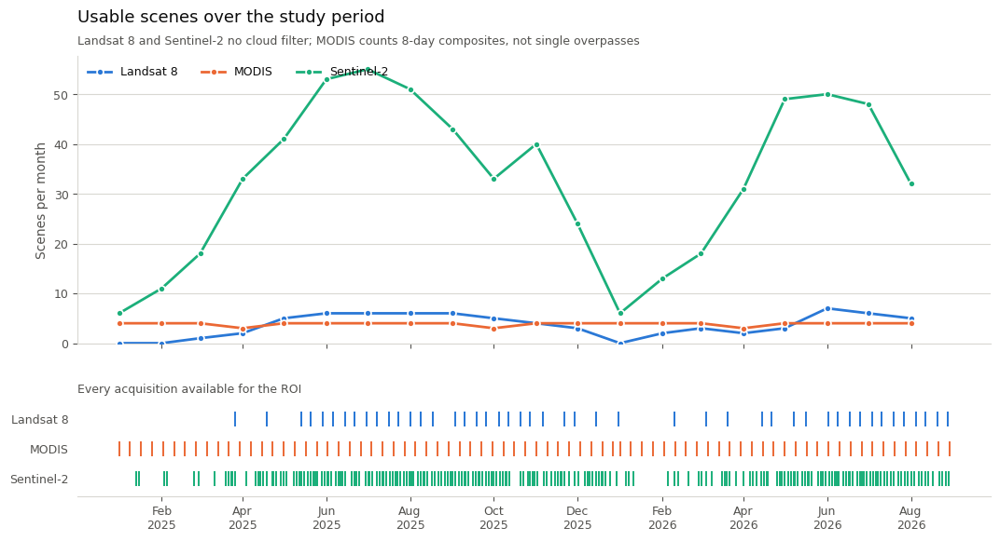

In [15]:
# ---------------------------------------------------------------------------
# ¿Cuántas escenas utilizables nos da cada sensor durante el período de estudio?
# ---------------------------------------------------------------------------
# Es la resolución temporal hecha medible: en lugar de citar la revisita
# nominal (16 / 8 / 5 días) contamos las escenas que realmente pasaron los
# filtros, mes a mes. Ejecute esta celda DESPUÉS de los bloques de l8, modis y s2.
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- Entradas -----------------------------------------------------------------
# Una entrada por sensor: la etiqueta que ve el lector, la ee.ImageCollection
# ya filtrada y enmascarada arriba, y el color usado para ella en cada panel
# y en cada leyenda, para que la vista pueda seguir un sensor en toda la figura.
# Sensor, colección, color
SENSORS = [
    ("Landsat 8",  l8,    "#2a78d6"),
    ("MODIS",      modis, "#eb6834"),
    ("Sentinel-2", s2,    "#1baf7a"),
]

# Earth Engine guarda los metadatos del lado del servidor. aggregate_array() reúne el
# tiempo de adquisición de cada imagen de la colección en una sola lista, así que una
# llamada a getInfo() es suficiente - nunca haga un bucle con getInfo() sobre las imágenes.
# Las marcas de tiempo vuelven como milisegundos desde 1970 (época Unix).
def acquisition_dates(collection):
    # Traer todas las marcas de tiempo de adquisición desde el servidor en una sola llamada
    stamps = collection.aggregate_array("system:time_start").getInfo()
    return pd.to_datetime(sorted(stamps), unit="ms")

# Grilla mensual que cubre todo el período de estudio, para que los meses vacíos aparezcan como cero
months = pd.date_range(START, END, freq="MS", inclusive="left")

# --- Conteo -------------------------------------------------------------------
# Para cada sensor construimos tres cosas:
#   dates[name]    - cada fecha de adquisición, usada para la franja de marcas de abajo;
#   monthly[name]  - escenas por mes calendario, reindexadas sobre la grilla completa para que
#                    un mes sin escenas utilizables aparezca como 0 en lugar de
#                    desaparecer de la línea;
#   summary        - los números que responden "¿con qué frecuencia, realmente?": los vacíos
#                    entre escenas consecutivas son lo que el usuario realmente
#                    percibe, y el vacío más largo suele ser una temporada nublada.
dates, monthly, summary = {}, {}, []
for name, collection, _ in SENSORS:
    d = acquisition_dates(collection)
    dates[name] = d
    monthly[name] = (pd.Series(1, index=d).resample("MS").sum()
                       .reindex(months, fill_value=0))
    gaps = d.to_series().diff().dt.days.dropna()   # días entre escenas consecutivas
    summary.append({
        "Sensor": name,
        "Scenes": len(d),
        "Scenes / month": round(len(d) / len(months), 1),
        "Median gap (days)": round(gaps.median(), 1) if len(gaps) else None,
        "Longest gap (days)": int(gaps.max()) if len(gaps) else None,
    })

# Una columna por sensor, una fila por mes - listo para graficar y mostrar
monthly = pd.DataFrame(monthly, index=months)

# --- Figura: conteos mensuales (arriba) + adquisiciones individuales (abajo) --------
# Dos paneles apilados que comparten el mismo eje de tiempo: el de arriba agrega
# (cuántas escenas por mes), el de abajo muestra los eventos individuales (cuándo).
# Paleta atenuada compartida para que el contraste lo den los datos y no los elementos decorativos.
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d2"

fig, (ax, ax_strip) = plt.subplots(
    2, 1, figsize=(11, 6.4), sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.30})

# Panel superior: una línea por sensor. Los bordes blancos de los marcadores mantienen los puntos legibles
# donde se cruzan las tres líneas.
for name, _, color in SENSORS:
    ax.plot(monthly.index, monthly[name], color=color, linewidth=2,
            marker="o", markersize=5, markeredgecolor="white",
            markeredgewidth=1.2, label=name, zorder=3)

# Estilo del panel superior: solo grilla horizontal, sin marco superior/derecho, y un
# título más una leyenda de una línea que indica qué se está contando.
ax.set_ylabel("Scenes per month", fontsize=10, color=MUTED)
ax.set_ylim(bottom=0)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color(GRID)
ax.tick_params(colors=MUTED, labelsize=9)
ax.legend(frameon=False, loc="upper left", fontsize=9, ncol=3,
          labelcolor=INK)
ax.set_title("Usable scenes over the study period", fontsize=13,
             color=INK, loc="left", pad=26)
ax.text(0, 1.03, "Landsat 8 and Sentinel-2 no cloud filter; "
                 "MODIS counts 8-day composites, not single overpasses",
        transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")

# Franja inferior: una marca por adquisición - el patrón de revisita en sí
# Cada sensor tiene su propia línea horizontal (el eje y está invertido para que el orden coincida con
# la leyenda de arriba). La densidad de las marcas ES la resolución temporal, y
# un vacío blanco visible es un período sin ninguna imagen utilizable.
for i, (name, _, color) in enumerate(SENSORS):
    y = len(SENSORS) - 1 - i
    ax_strip.plot(dates[name], [y] * len(dates[name]), linestyle="none",
                  marker="|", markersize=11, markeredgewidth=1.4, color=color)

# Estilo de la franja: nombres de los sensores en lugar de marcas numéricas, un eje de fechas
# rotulado cada dos meses y casi sin marco - es un gráfico de eventos.
ax_strip.set_yticks(range(len(SENSORS)))
ax_strip.set_yticklabels([s[0] for s in SENSORS][::-1], fontsize=9, color=INK)
ax_strip.set_ylim(-0.6, len(SENSORS) - 0.4)
ax_strip.set_title("Every acquisition available for the ROI", fontsize=9,
                   color=MUTED, loc="left", pad=6)
ax_strip.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax_strip.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
for side in ("top", "right", "left"):
    ax_strip.spines[side].set_visible(False)
ax_strip.spines["bottom"].set_color(GRID)
ax_strip.tick_params(colors=MUTED, labelsize=9, left=False)

fig.subplots_adjust(left=0.09, right=0.98, top=0.86, bottom=0.12)
plt.show()

# --- Vista de tabla -------------------------------------------------------------
# La misma información como números: el resumen responde "¿qué sensor observa
# este sitio con más frecuencia, y cuál es la peor espera?", mientras que la tabla mensual
# (transpuesta para que los sensores sean filas) muestra el patrón estacional detrás de las
# líneas - normalmente la época de lluvias, donde el filtro de nubes vacía la fila.
# print("\nSummary")
# display(pd.DataFrame(summary).set_index("Sensor"))
# print("\nScenes per month")
# display(monthly.T)

In [16]:
# ---------------------------------------------------------------------------
# Lado a lado: la misma composición, el mismo período, tres tamaños de píxel
# ---------------------------------------------------------------------------
# Reutilizamos las composiciones de mediana construidas arriba - no se necesita un nuevo filtrado.
# geemap.linked_maps sincroniza el desplazamiento y el zoom entre los paneles, así que cada
# diferencia que usted ve viene del sensor, no del encuadre.
for _t in ("north", "south", "east", "west"):
    geemap.Map.class_traits()[_t].allow_none = True

comparison = geemap.linked_maps(
    rows=1, cols=3, height="420px",
    center=[CENTER_LAT, CENTER_LON], zoom=13,
    ee_objects=[modis_median, l8_median, s2_median],
    vis_params=[md_swir,l8_swir,  s2_swir],
    labels=["MODIS - 500 m", "Landsat 8 - 30 m", "Sentinel-2 - 20 m"],
    label_position="topright",
)

comparison

GridspecLayout(children=(Output(layout=Layout(grid_area='widget001')), Output(layout=Layout(grid_area='widget0…

### Qué observar

Acérquese progresivamente (13 -> 15 -> 17) y observe cómo aparecen los píxeles:

1. **La orilla.** A 500 m el límite agua/tierra es una franja ancha de píxeles mixtos; a
   30 m se convierte en una línea nítida; a 20 m se pueden seguir pequeñas ensenadas e islas.
2. **Patrones de las parcelas.** Las parcelas individuales son visibles en Sentinel-2, agrupadas en bloques en
   Landsat, y desaparecen por completo en MODIS - un píxel MODIS puede promediar una parcela de riego, una
   parcela seca y un camino en un solo valor sin sentido. Este es el problema del **píxel mixto**,
   y es la razón principal por la que los embalses pequeños y los canales estrechos no se pueden mapear con MODIS.
3. **Los colores coinciden.** A pesar de la diferencia de resolución, el agua es negra, la vegetación verde y
   el suelo desnudo magenta en los tres paneles. **El comportamiento espectral no depende del sensor** -
   solo de la física de la reflectancia. La resolución cambia *qué tan bien podemos ver* una superficie,
   no *de qué está hecha*.
4. **Los tonos no son idénticos.** Los anchos de banda difieren (el SWIR-1 de MODIS es más estrecho que
   la B6 de Landsat), cada producto usa una corrección atmosférica diferente, y cada mediana se construye
   a partir de un número diferente de escenas. Por eso **las comparaciones entre sensores necesitan armonización**
   antes de cualquier uso cuantitativo.

> **La compensación, otra vez:** si necesita saber *dónde* está algo, elija Sentinel-2.
> Si necesita saber *cuándo* cambió, elija MODIS. Si necesita saber *cómo evolucionó
> a lo largo de décadas*, elija Landsat.

---

## Referencias

**Catálogo de datos**

- Landsat 8 Collection 2 L2: <https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC08_C02_T1_L2>
- MODIS MOD09A1 v061: <https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD09A1>
- Sentinel-2 SR Harmonized: <https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED>

**Herramientas y documentación**

- Registro en Earth Engine: <https://code.earthengine.google.com/register>
- Guía de Python de Earth Engine: <https://developers.google.com/earth-engine/guides/python_install>
- Documentación y tutoriales de geemap: <https://geemap.org>
- Algoritmo Sentinel-2 L2A (clases SCL): <https://sentinels.copernicus.eu/web/sentinel/technical-guides/sentinel-2-msi/level-2a/algorithm>
- Factores de escala de Landsat Colección 2: <https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products>

**Lecturas de base**

- Jensen, J.R. (2015). *Introductory Digital Image Processing: A Remote Sensing Perspective*, 4th ed. Pearson.
- Lillesand, T., Kiefer, R.W., Chipman, J. (2015). *Remote Sensing and Image Interpretation*, 7th ed. Wiley.
- Gorelick, N. et al. (2017). Google Earth Engine: Planetary-scale geospatial analysis for everyone. *Remote Sensing of Environment*, 202, 18-27.
- Wu, Q. (2020). geemap: A Python package for interactive mapping with Google Earth Engine. *Journal of Open Source Software*, 5(51), 2305.
